# Atelier Variant
*École de bioinformatique IFB-INSERM-INRAe 2025*

**Formatrices et Tutrices**
* Gabriele Adam - INRAE - gabriele.adam@inrae.fr
* Pauline François - ANSES - pauline.francois@anses.fr
* Elodie Girard - Curie - elodie.girard@curie.fr
* Maria Bernard - INRAE - maria.bernard@inrae.fr

<style>
/* Blocs markdown fenced */
.reveal pre code {
    font-size: 1.8em !important;
    line-height: 2.1 !important;
}
/* Sorties des cellules de code */
.jp-OutputArea-output,
.jp-OutputArea-output pre {
    font-size: 18px !important;
    max-height: 30vh !important;
    overflow-y: auto !important;
    overflow-x: auto !important;
    white-space: pre !important;
    width: 100% !important;
    box-sizing: border-box !important;
}
.jp-OutputArea-output table,
.jp-OutputArea-output table th,
.jp-OutputArea-output table td {
    font-size: 16px !important;
}

/* Code source des cellules In[ ] */
.jp-InputArea .highlight {
    overflow-x: auto !important;
    max-width: 100%;
    display: block;
}
.jp-InputArea .highlight pre {
    font-size: 18px !important;
    white-space: pre !important;
}
</style>

# Introduction

## I. Définition

<div style="display:flex; align-items:center; gap:30px;">
  <img src="https://www.genome.gov/sites/default/files/inline-images/prs-var1_1.jpg" width=700>
</div>

* **SNV/SNP** : Single Nucleotide Variant / Single Nucleotide Polymorphism
* **INDEL** : insertion ou délétion d'une ou plusieurs bases
* **MNV** : Multi-Nucleotide Variant
* **SV** : Structural Variant
* **CNV** : Copy Number Variation

## II. Processus d'analyse et programme

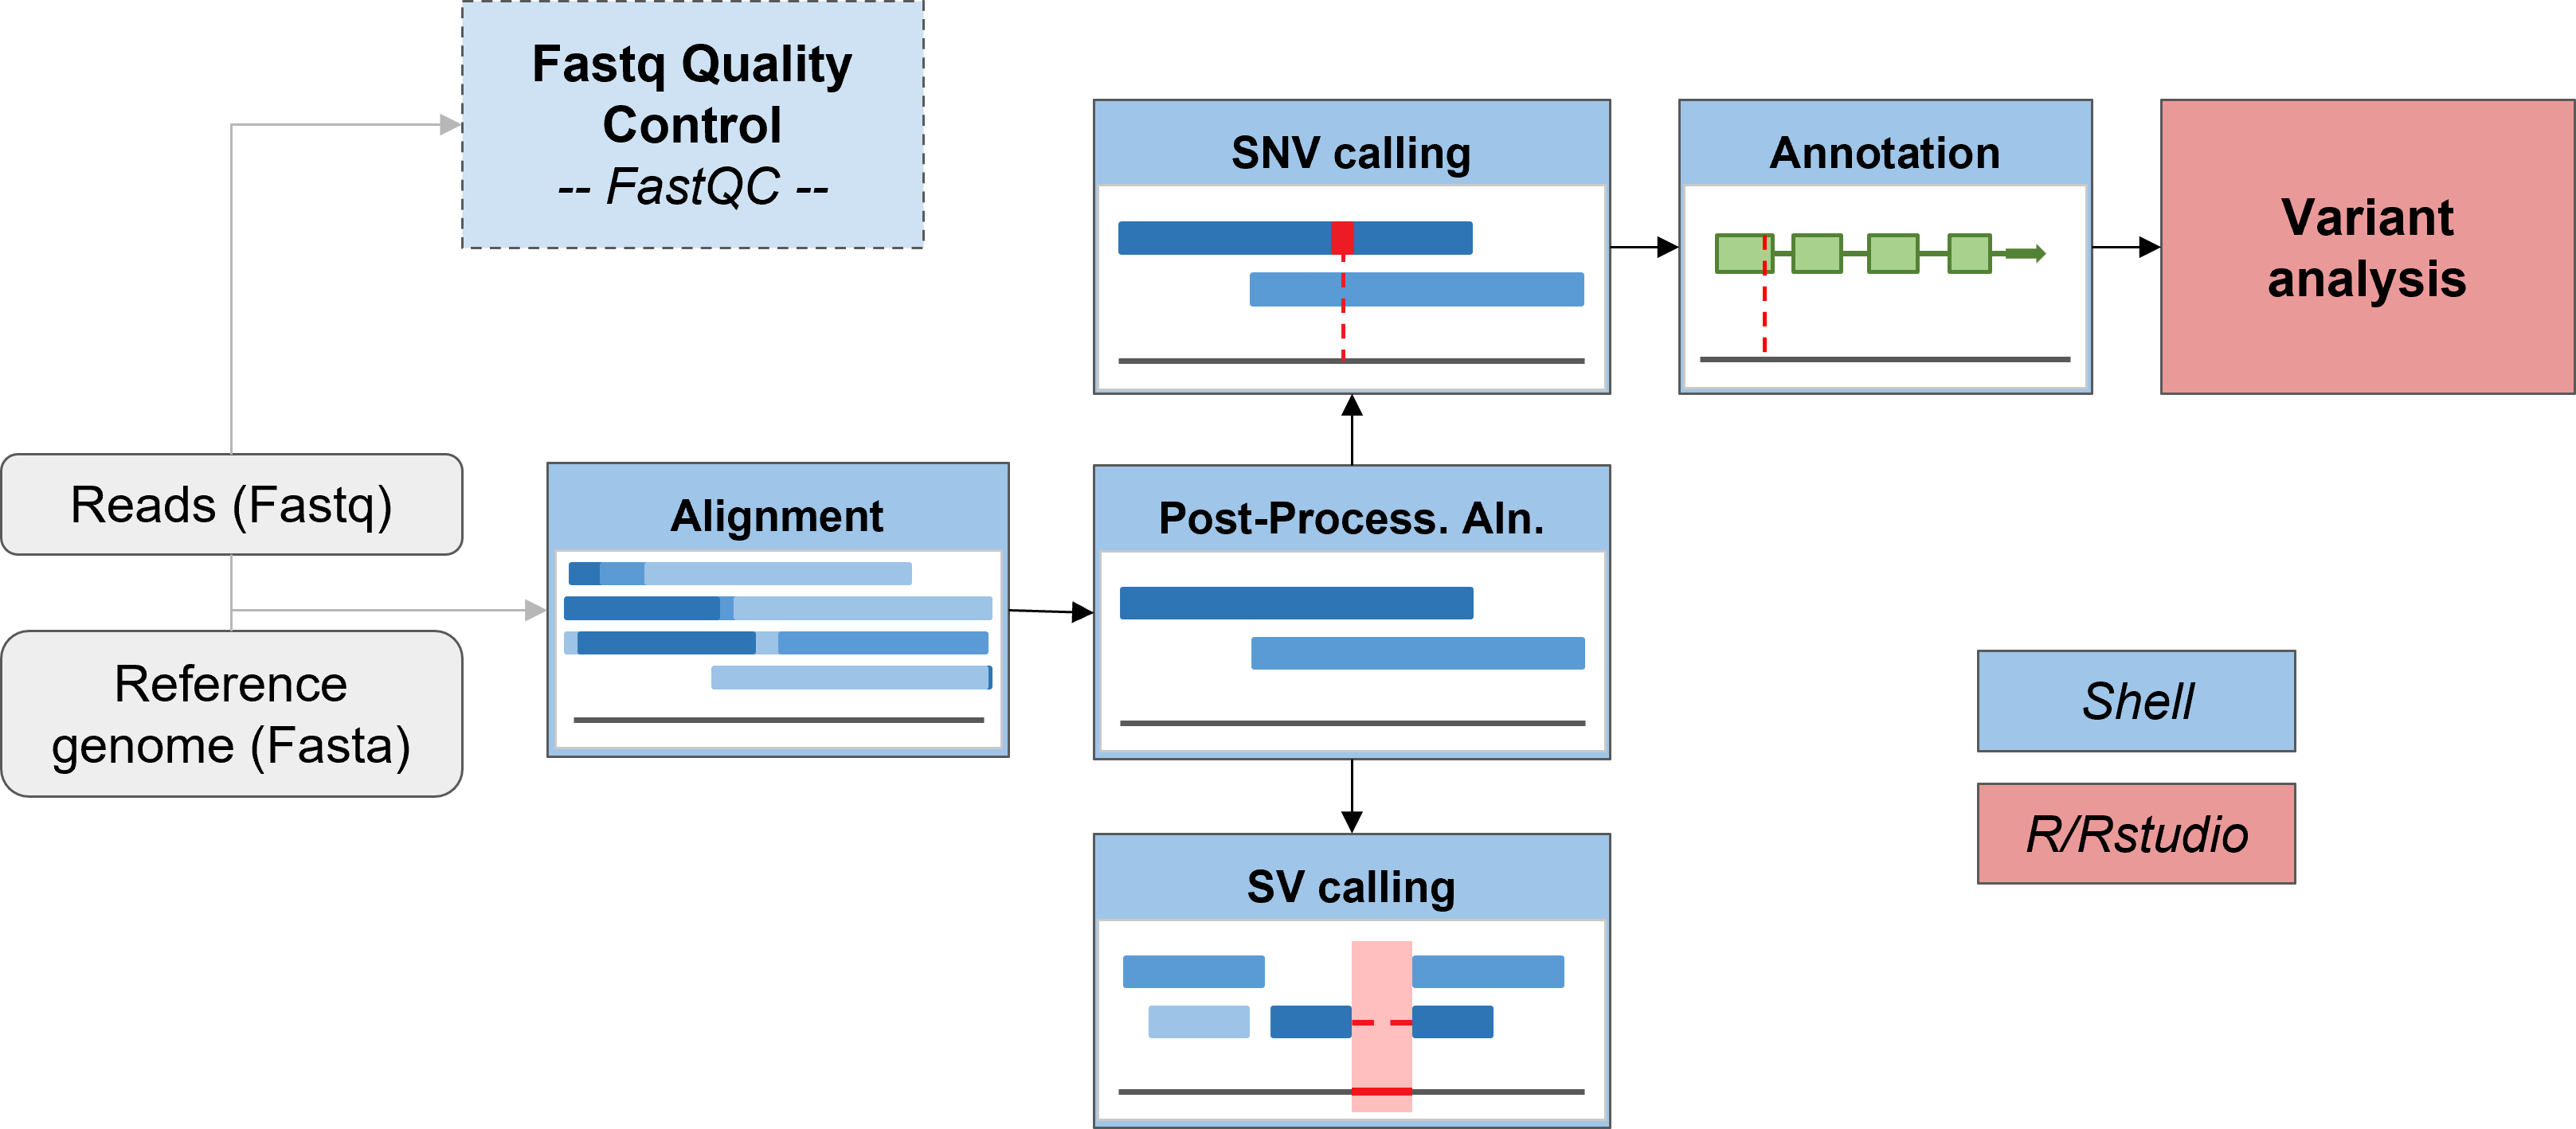

Nos objectifs sont : 
1. Vous familiariser avec les outils de bioinformatique pour 
    * La détection des petites variations génomiques et leur annotation fonctionnelle (**mardi**)
    * La détection des variations structurales (**mardi**)
2. Vous familiariser avec différents environnements informatiques :
    * Le terminal et la ligne de commande shell (**toute la semaine !!**)
    * La manipulation de données (ici petits variants) avec R (**mercredi**)
3. Automatiser les traitements (workflow) grâce à un script (**jeudi**).

## III. Initialisation de l'atelier variant

### Connexion

Aller sur : https://ondemand.cluster.france-bioinformatique.fr/pun/sys/dashboard

Créer une session Jupyter avec les ressources suivantes :
* Reservation:EB3IN1_2026
* Account: 2621_eb3in1_2026
* Number of CPUs: 4
* Amount of memory: 10G
* Number of hours : 12

### Notes sur Jupyter

* Pour exécuter une cellule de code, positionnez-vous dessus et tapez CTRL+Enter
* Lorsqu'une commande est en cours, vous avez le symbole `[*]` à gauche de la cellule et un sablier sur l'onglet de votre navigateur ... patience !

### Initier un nouveau projet

Lors d'un nouveau projet, pour travailler sur le cluster de l'IFB, vous devez [demander la création d'un espace projet dédié](https://my.cluster.france-bioinformatique.fr/manager2/project) : /shared/projects/<span style="color: #eb2854">[VOTRE_PROJET]</span> 

Dans le Terminal, positionnez-vous dans votre répertoire projet avec la commande `cd`.

In [ ]:
# Remplacer *mon_projet* par le nom de votre projet!!!
cd /shared/projects/mon_projet

Pour savoir où vous êtes, utilisez la commande `pwd`.

Si ce n'est pas fait automatiquement, grâce au menu de gauche déplacez-vous également dans votre répertoire projet.

Dans le cadre de cette école/atelier, ce projet va contenir 4 sous-projets : 3 correspondant aux différents TP, et 1 à votre projet tutoré.

Copiez le dossier **/shared/projects/2621_eb3in1_2026/atelier_variant** dans votre projet, avec la commande `cp -r`

In [ ]:
cp -r /shared/projects/2621_eb3in1_2026/atelier_variant/  ./

Vérifiez le contenu du dossier **atelier_variant**, avec la commande `ls`.
<div style="background-color: #e7f3fe; border-left: 6px solid #2196F3; padding: 10px;">
    ℹ️ <strong>Remarque</strong><br>
    Vous pouvez ajouter quasiment systématiquement les options :
    <ul>
        <li> <code>-l</code> : pour le format listing</li>
        <li> <code>-rt</code> : pour trier les fichiers par date de modification (<code>-r</code> pour reverse, les plus récents en dernier)</li>
        <li> <code>-h</code> : pour exprimer le poids des fichiers dans un langage "human readable"</li>
    </ul>
</div>

In [5]:
ls atelier_variant

00_Introduction_EN.ipynb  TP_small_variants	  TP_variant_process_R
00_Introduction_FR.ipynb  TP_structural_variants


* TP_small_variants : TP détection des petites variations génomiques
* TP_structural_variants : TP détection des variations structurales
* TP_variant_process_R : TP manipulation des VCF sous R

Les fichiers `.ipynb` sont des fichiers jupyter notebook qui correspondent aux supports de cours.

Déplacez-vous dans le dossier **atelier_variant** avec la commande `cd`.

In [ ]:
cd atelier_variant

## IV. Rappels sur l'activation des outils

Nous allons utiliser de nombreux outils bioinformatiques différents.

Par défaut, aucun n'est activé. Pour chaque outil il va falloir **charger un module**.

Pour trouver un module **utilisez le Terminal** et la commande `module avail`. Par exemple pour l'outil bwa :

In [ ]:
module avail bwa

Pour charger un module, utilisez la commande `module load`, par exemple :

In [ ]:
module load bwa-mem2/2.2.1

Vous pouvez cumuler plusieurs outils en lançant plusieurs commandes `module load` mais attention certains sont incompatibles entre eux, ce qui nécessite de **décharger** le ou les modules. 
- pour décharger 1 module 

In [ ]:
module unload bwa-mem2/2.2.1

* pour décharger tous les modules

In [ ]:
module purge